# K-Armed-Bandit 

- Author: Ethan Cao
- Description: 
  - replicating figure 2.6 by comparing three algorithms: **$\epsilon$-greedy**, **UCB (Upper Confidence Bound)**, and **greedy with optimistic initiation**
  - This notebook **reuses** the `k-armed_bandit.ipynb` notebook with the same  `BanditEnvironment` class, with the same `training_loop()` and `run_experiment()` method.
  - In the first notebook (`k_armed_bandit.ipynb`) we only implemented a comparison between a greedy way of choosing rewards vs a slightly non-greedy way of choosing rewards, with **different variations of $\epsilon$ values**. In this notebook, we implement and compare **3 different algorithmic reward choosing strategies**

## Bandit Environment
- We first define the environment of the multi-armed bandit game with its **reward distributions**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

class BanditEnvironment:
    # constructor for all the variables in this game
    def __init__(self, k=10, seed=None):
        # k number of arms that this bandit game has
        self.k = k
        # defining a random number generator with a set seed
        self.rng = np.random.default_rng(seed)
        # defining the true distribution of the reward
        # samples one true expected reward per arm from N(0, 1), mean 0 and std 1
        self.q_t = self.rng.normal(loc=0, scale=1, size=k)
        # define the variable that stores the index of the arm with the highest true expected reward
        self.optimal_action = np.argmax(self.q_t)

    # function that generates a reward each step
    def step(self, action):
        # samples a reward centered on the arm's true value with std 1
        return self.rng.normal(loc=self.q_t[action], scale=1)


- In the code above, when we create an environment, we generate one true mean reward for each arm: `self.q_t = self.rng.normal(loc=0, scale=1, size=k)`
- for example, for three arms, we get: `self.q_t = np.array([0.2, -0.8, 1.5])`
                                                             
                                                         0     1    2
- These numbers describe how *rewarding* each arm is on average.
- Each time an arm is selected, we generate a new reward: `return self.rng.normal(loc=self.q_t[action], scale=1)`
- if `action = 2`, meaning we chose the second index arm, the code finds the normal distribution of rewards centered around index 2 arm's mean true reward (which is `1.5`). By **repeatedly** sampling from this distribution, or selecting arm 2, the average of those sampled rewards gradually approaches `1.5`. This is also referred by the **law of big numbers**.
- for example, repeatedly sampling a normal distribution centered around index 2 arm's mean, we get `1.9`, `0.6`, and `2.1`, ... and averaging those would gradually approach `1.5`.

## Epsilon Greedy Agent
- Here we initialize the Epsilon Greedy Agent who will be playing the game and optimizing its result based on the rewards it receives.
- We define the agent to use a strategy of not purely being *Greedy*. Instead, we define an `epsilon` variable that determines to what percentage of times would the agent choose an arm at random that *does not* return the most rewards. 

In [2]:
class NotSoGreedyAgent:
    def __init__(self, k=10, epsilon=0.1, seed=None):
        self.k = k
        self.epsilon = epsilon
        self.rng = np.random.default_rng(seed)

        # creates an array of k numbers of 0s initially
        # these will later be stored with the estimated mean reward per arm.
        self.Q = np.zeros(k)

        # creates an array of arm selection count per arm (in integer)
        self.N = np.zeros(k, dtype=int)

    # a method defines the rule for choosing an arm
    def select_action(self):

        # # the rule to conduct exploration instead of exploitation:
        # # if the randomly drawn probability is between 0.0 to 0.1, execute the exploration strategy
        # if self.rng.random() < self.epsilon:
        #     # randomly choose an arm 
        #     return self.rng.integers(self.k)

        # # otherwise, if the randomly drawn value is between 0.1 to 1.0, execute the greedy strategy
        # # finds the indicies of all arms tied for the highest estimated reward
        # best_actions = np.flatnonzero(self.Q == self.Q.max())


        # # exploits by choosing randomly among those best arms in a greedy manner
        # return self.rng.choice(best_actions)

        # picks the arm choosing strategy based on the existing probability
        decision = self.rng.choice(["explore","greedy"], p=[self.epsilon, 1-self.epsilon])
        if decision == "explore":
            # randomly choose an arm
            return self.rng.integers(self.k)
        else:
            # np.flatnonzero() returns indices where an array's values are nonzero
            # here we return non zero indices of arm reward values that are equal to the max reward of this array
            best_actions = np.flatnonzero(self.Q == self.Q.max())
            # randomly picks one of the tied arms (if any)
            return self.rng.choice(best_actions)

    # a method that receives the chosen arm and its current estimated/observed reward
    def update(self, action, reward):
        # update the number of times this (chosen) arm has been chosen
        self.N[action] += 1
        # update the estimated mean reward for that particular chosen arm
        # calculated as: the difference between observed reward and the current estimated reward / the number of times the arm is chosen
        self.Q[action] += (reward - self.Q[action])/self.N[action]

- As shown above, we also define the agent with the variable `Q` that records the mean estimated reward for each arm at each step, and the variable `N` records the number of times each arm is selected since the start for each arm at each step.
- we define a method `select_action` that selects an arm based on the define `epsilon` that will influence the probability of choosing and making the agent *less greedy*
- we define a method `update` that determines how the next step estimated reward is calculated:
$$New \ estimate = old \ estimate + \frac{observed \ reward - old \ estimate}{num \ of \ times \ this \ arm \ was \ chosen}$$

## UCB Agent

- UCB = Upper Confidence Bound.
- This algorithm chooses the arm with the highest score: $\text{score}(a) = Q(a) + c\sqrt{\frac{\ln t}{N(a)}}$.
  - $Q(a)$: the arm's estimated mean reward.
  - $N(a)$: how many times that arm has been selected.
  - $t$: the current step, starting at 1.
  - $c$: controls the degree of exploration.
- The first term is the estimated reward, while the second term is the exploration bonus.
  
### the bonus term rationale
- It is a term that measures **how uncertain we are about an arm's estimated reward**
- $\frac{1}{\sqrt{N(a)}}:$ averages become more reliable as we collect more observations, the typical uncertainty shrinks as the denominator increase.
- $\sqrt{\ln t}$: gradually increasing the bonus as time (t) increases. If we neglect an arm, its count stays fixed while $t$ increases, therefore it would artificially increase the reward of the neglected arm and encourage the agent to consider it.

## UCB example

- *Consider two arms. We have taken 4 actions and are choosing the next arm at step $t=5$, with $c=2$.*
- Arm A has returned rewards of 2, 4, and 3, so $Q(A)=(2+4+3)/3=3$.
- Arm B has returned one reward of 2.5, so $Q(B)=2.5$.

| Arm | Observed rewards | Count $N(a)$ | Estimate $Q(a)$ | Bonus $c\sqrt{\frac{\ln t}{N(a)}}$ | UCB score |
| :--- | :--- | ---: | ---: | ---: | ---: |
| A | 2, 4, 3 | 3 | 3.0 | 1.465 | 4.465 |
| B | 2.5 | 1 | 2.5 | 2.537 | **5.037** |

- For Arm A: $\text{score}(A)=3+2\sqrt{\frac{\ln(5)}{3}}\approx4.465$.
- For Arm B: $\text{score}(B)=2.5+2\sqrt{\frac{\ln(5)}{1}}\approx5.037$.
- UCB chooses **Arm B**: its estimated reward is lower, but its exploration bonus is larger because it has been tried less.
- If B now returns 3.5, its count becomes $N(B)=2$ and its estimate becomes $Q(B)=(2.5+3.5)/2=3$.
- At the next step, $t=6$, recalculate the scores using the updated counts and estimates.

- *For an untried arm, $N(a)=0$, select untried arms first to avoid dividing by zero.*


In [3]:
class UCBAgent:
    def __init__(self, k = 10, c = 2, seed = None):
        self.k = k
        self.c = c
        self.rng = np.random.default_rng(seed)

        # estimated mean reward for each arm
        self.Q = np.zeros(k)
        # number of times each arm has been chosen
        self.N = np.zeros(k, dtype=int)
        # total number of completed steps 
        self.time = 0

    # choose an arm using its estimated reward and exploration bonus
    def select_action(self):
        # find arms that have never been selected
        untried_arms = np.flatnonzero(self.N == 0)

        # try every arm before calculating scores to avoid division by zero
        if len(untried_arms >0):
            return self.rng.choice(untried_arms)

        # the current step is one more than the completed step count
        t = self.time + 1

        # calculate a bonus and score for every arm
        bonus = self.c * np.sqrt(np.log(t) / self.N)
        scores = self.Q + bonus

        # find all arms tied for the highest score
        best_arms = np.flatnonzero(scores == scores.max())
        return self.rng.choice(best_arms)

    # update the chosen arm using the observed reward
    def update(self, action, reward):
        previous_average = self.Q[action]
        previous_count = self.N[action]

        # recover the total of this arm's previous rewards
        previous_total = previous_average * previous_count

        # include the new reward and selection
        new_total = previous_total + reward
        new_count = previous_count + 1

        # store this arm's new average and count
        self.Q[action] = new_total / new_count
        self.N[action] = new_count

        # count the completed step across all arms
        self.time += 1

## Optimistic Agent

- *Greedy with optimistic initialization starts every arm's estimate at a high value, such as 5 instead of 0.*
- When a chosen arm returns a reward below its current estimate, that estimate decreases. Untried arms keep their high estimates and become more attractive, even though the agent always acts greedily.
- This encourages exploration by making arms that have not been tried look promising compared with arms whose estimates have dropped after receiving rewards.
- An estimate does not decrease just because an arm has been chosen many times. The observed reward determines the direction of the update.
- The learning rate $\alpha$ controls **how far** the estimate moves toward the observed reward

$$
Q_{\text{new}}(a) = Q_{\text{old}}(a) + \alpha\left[R - Q_{\text{old}}(a)\right]
$$

- $Q_{\text{old}}(a)$: the chosen arm's estimate before the update.
- $R$: the reward just observed from that arm.
- $R-Q_{\text{old}}(a)$: the difference between the observed reward and the current estimate.
- If that difference is negative, the estimate decreases; if positive, it increases; if zero, it stays the same.
- With $\alpha=0.1$, the estimate moves 10% of the way from its old value toward the new reward.
- We can also write the update as a weighted average: $Q_{\text{new}}(a)=(1-\alpha)Q_{\text{old}}(a)+\alpha R$. With $\alpha=0.1$, this gives 90% weight to the old estimate and 10% to the new reward.

## Optimistic initialization example

- *Consider three arms whose estimates all start at 5, with $\alpha=0.1$.*
- All estimates are tied initially, so the greedy agent randomly chooses one of the three arms. Suppose it chooses arm 0 and receives a reward of 1.

$$
Q_{\text{new}}(0)=5+0.1(1-5)=5-0.4=4.6
$$

| Arm | Estimate before the pull | Observed reward on this step | Estimate after the update |
| :--- | ---: | :--- | ---: |
| 0 | 5.0 | 1 | 4.6 |
| 1 | 5.0 | Not selected | 5.0 |
| 2 | 5.0 | Not selected | 5.0 |

- The next greedy choice is arm 1 or arm 2, because their estimates of 5 are higher than arm 0's estimate of 4.6.

In [4]:
class OptimisticAgent:
    def __init__(self, k=10, initial_value=5, alpha=0.1, seed=None):
        self.k = k
        self.alpha = alpha
        self.rng = np.random.default_rng(seed)

        # start every arm with the same optimistic reward estimate
        # use floats so the estimates can store decimal values after updates
        self.Q = np.full(k, initial_value, dtype=float) #np. full creates an array filled with the same value

    # choose the arm with the highest estimated reward
    def select_action(self):
        highest_estimate = self.Q.max()
        # find all arms tied for the highest estimate
        best_arms = np.flatnonzero(self.Q == highest_estimate)
        # randomly choose one of those arms if there is a tie
        return self.rng.choice(best_arms)

    # move the chosen arm's estimate toward its observed reward
    def update(self, action, reward):
        previous_estimate = self.Q[action]
        # the difference determines whether the estimate goes up or down
        difference = reward - previous_estimate
        # alpha controls how far the estimate moves toward the reward
        adjustment = self.alpha * difference
        self.Q[action] = previous_estimate + adjustment


## Training Loop
- Finally, we reach the training loop, we will be defining a loop as to how many steps should the multi-armed bandit game to be played, and observe the trained output

In [ ]:
def training_loop(agent, steps=1000):
    # create a new environment with the same number of arms as the agent
    environment = BanditEnvironment(k=agent.k)

    # record one reward per step
    rewards = np.zeros(steps)

    for step in range(steps):
        # for each step the agent selects an action
        action = agent.select_action()
        # selects a reward
        reward = environment.step(action)
        # the agent gets updated by the action and reward
        agent.update(action, reward)
        # reocrd the reward for each step
        rewards[step] = reward

    # return one number: average reward over this entire run
    return rewards.mean()

In [ ]:
def run_experiment(method, parameters, runs=2000, steps=1000):
    # store one average reward for each parameter value
    average_rewards = np.zeros(len(parameters))

    for i, parameter in enumerate(parameters):
        total_reward = 0

        for run in range(runs):
            # create a new agent for every run
            if method == "epsilon_greedy":
                agent = NotSoGreedyAgent(epsilon=parameter)

            elif method == "ucb":
                agent = UCBAgent(c=parameter)

            elif method == "optimistic":
                agent = OptimisticAgent(
                    initial_value=parameter,
                    alpha=0.1
                )

            else:
                raise ValueError("nope")

            # get the average reward over this run's steps
            run_average = training_loop(agent, steps=steps)
            total_reward += run_average

        # average the results across all runs for this parameter
        average_rewards[i] = total_reward / runs

    return average_rewards

## Run experiment

In [ ]:
# testing whether ucb produces one average reward for each parameter value 
test_rewards = run_experiment(
    method="ucb",
    parameters=[0.5, 1, 2],
    runs=10,
    steps=100
)

print(test_rewards)

[1.31443968 1.18872123 1.10411175]


In [ ]:
# parameter values used for each curve in Figure 2.6
epsilon_values = [1/128, 1/64, 1/32, 1/16, 1/8, 1/4]
c_values = [1/16, 1/8, 1/4, 1/2, 1, 2, 4]
initial_values = [1/4, 1/2, 1, 2, 4]

# run each algorithm with its different parameter values

epsilon_rewards = run_experiment(
    method="epsilon_greedy",
    parameters=epsilon_values,
    runs=2000,
    steps=1000
)

ucb_rewards = run_experiment(
    method="ucb",
    parameters=c_values,
    runs=2000,
    steps=1000
)

optimistic_rewards = run_experiment(
    method="optimistic",
    parameters=initial_values,
    runs=2000,
    steps=1000
)

## Visualization

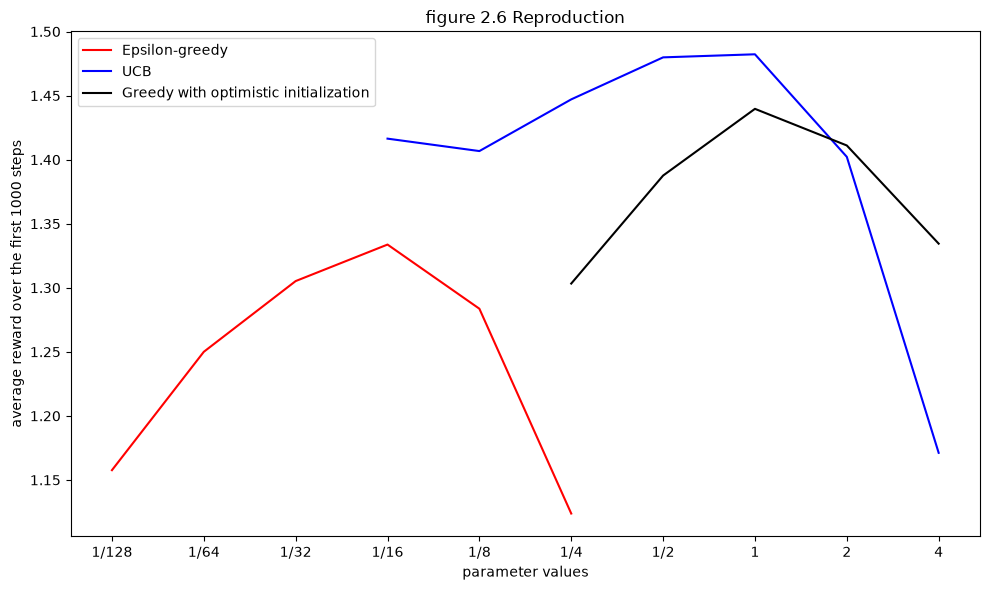

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))

# draw one curve for each algorithm
ax.plot(epsilon_values, epsilon_rewards, color="red", label="Epsilon-greedy")

ax.plot(c_values, ucb_rewards,color="blue", label="UCB")

ax.plot(initial_values, optimistic_rewards,color="black", label="Greedy with optimistic initialization")

# give equal spacing to parameter values 
ax.set_xscale("log", base=2)

# show fractions on the x-axis to match the figures
tick_values = [1/128, 1/64, 1/32, 1/16, 1/8, 1/4, 1/2, 1, 2, 4]
tick_labels = ["1/128", "1/64", "1/32", "1/16", "1/8", "1/4", "1/2", "1", "2", "4"]
ax.set_xticks(tick_values)
ax.set_xticklabels(tick_labels)

ax.set_xlabel("parameter values")
ax.set_ylabel("average reward over the first 1000 steps")
ax.set_title("figure 2.6 Reproduction")
ax.legend()

plt.tight_layout()
plt.show()

- This graph shows the best parameter value for each type of reward algorithm that obtained the best rewards. it also shows that UCB could obtain the highest average reward compared to the rest of the two algorithms. All three algorithms exhibit signfiicant performance drops as parameter values changes. 